RNN (IMDB-2)

IMDb Rating Prediction (Regression)
SimpleRNN vs LSTM vs GRU

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
import pickle
import re
import string

In [2]:
df= pd.read_csv(r"L:\4th sem\Mission Scopus\ML Datasets\IMDB\IMBD.csv")

In [3]:
df.head()

,title,year,certificate,duration,genre,rating,description,stars,votes
0,Cobra Kai,(2018– ),TV-14,30 min,"Action, Comedy, Drama",8.5,Decades after their 1984 All Valley Karate Tou...,"['Ralph Macchio, ', 'William Zabka, ', 'Courtn...","177,031"
1,The Crown,(2016– ),TV-MA,58 min,"Biography, Drama, History",8.7,Follows the political rivalries and romance of...,"['Claire Foy, ', 'Olivia Colman, ', 'Imelda St...","199,885"
2,Better Call Saul,(2015–2022),TV-MA,46 min,"Crime, Drama",8.9,The trials and tribulations of criminal lawyer...,"['Bob Odenkirk, ', 'Rhea Seehorn, ', 'Jonathan...","501,384"
3,Devil in Ohio,-2022,TV-MA,356 min,"Drama, Horror, Mystery",5.9,When a psychiatrist shelters a mysterious cult...,"['Emily Deschanel, ', 'Sam Jaeger, ', 'Gerardo...","9,773"
4,Cyberpunk: Edgerunners,(2022– ),TV-MA,24 min,"Animation, Action, Adventure",8.6,A Street Kid trying to survive in a technology...,"['Zach Aguilar, ', 'Kenichiro Ohashi, ', 'Emi ...","15,413"


In [4]:
values= {"year":"(2016-2020)", "certificate":"TV-MV", "duration":"90 m"}
df.fillna(value=values, inplace=True)
df.head()

,title,year,certificate,duration,genre,rating,description,stars,votes
0,Cobra Kai,(2018– ),TV-14,30 min,"Action, Comedy, Drama",8.5,Decades after their 1984 All Valley Karate Tou...,"['Ralph Macchio, ', 'William Zabka, ', 'Courtn...","177,031"
1,The Crown,(2016– ),TV-MA,58 min,"Biography, Drama, History",8.7,Follows the political rivalries and romance of...,"['Claire Foy, ', 'Olivia Colman, ', 'Imelda St...","199,885"
2,Better Call Saul,(2015–2022),TV-MA,46 min,"Crime, Drama",8.9,The trials and tribulations of criminal lawyer...,"['Bob Odenkirk, ', 'Rhea Seehorn, ', 'Jonathan...","501,384"
3,Devil in Ohio,-2022,TV-MA,356 min,"Drama, Horror, Mystery",5.9,When a psychiatrist shelters a mysterious cult...,"['Emily Deschanel, ', 'Sam Jaeger, ', 'Gerardo...","9,773"
4,Cyberpunk: Edgerunners,(2022– ),TV-MA,24 min,"Animation, Action, Adventure",8.6,A Street Kid trying to survive in a technology...,"['Zach Aguilar, ', 'Kenichiro Ohashi, ', 'Emi ...","15,413"


In [5]:
df["rating"]= df["rating"].fillna(df["rating"].mean(), inplace=True)

C:\Users\DELL\AppData\Local\Temp\ipykernel_14628\1489462808.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df["rating"]= df["rating"].fillna(df["rating"].mean(), inplace=True)


In [6]:
# Remove commas from the rating column
df["votes"] = df["votes"].str.replace(",", "", regex=False)

# Convert the column to numeric (float)
# errors='coerce' will turn any unparseable values into NaN
df["votes"] = pd.to_numeric(df["votes"], errors="coerce")

In [7]:
# Now this will work because the column is numbers
df["votes"] = df["votes"].fillna(df["votes"].mean())

In [8]:
df.dropna(inplace=True)

In [9]:
df.isnull().sum()

title          0
year           0
certificate    0
duration       0
genre          0
rating         0
description    0
stars          0
votes          0
dtype: int64

In [10]:
df.shape

(9884, 9)

In [11]:
df["rating"].describe()

count    9884.000000
mean        6.764017
std         1.144538
min         1.700000
25%         6.200000
50%         6.764515
75%         7.500000
max         9.900000
Name: rating, dtype: float64

Text Cleaning

In [12]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_description"] = df["description"].apply(clean_text)

texts = df["clean_description"].values
ratings = df["rating"].values.astype("float32")

Tokenization & Padding

In [13]:
vocab_size = 10000
max_length = 150          # descriptions are short (avg ~150 chars)
embed_dim = 16
rnn_units = 32

In [14]:
tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(texts)

In [15]:
sequences = tokenizer.texts_to_sequences(texts)
X_pad = pad_sequences(sequences, maxlen=max_length, padding="post", truncating="post")

In [16]:
y= ratings

In [18]:
X_pad.shape, y.shape

((9884, 150), (9884,))

Split

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X_pad, y, test_size=0.2, random_state=42)

Model Creation and Training for SimpleRNN.

In [20]:
input_layer= Input(shape= (max_length,), name= "Input_Layer")
embedding_layer= Embedding(input_dim= vocab_size, output_dim= embed_dim, mask_zero= True, name= "Embedding_Layer")(input_layer)

In [21]:
rnn= SimpleRNN(units= rnn_units, return_sequences= False, return_state= False, name= "SimpleRNN_Layer")
embedding_layer_second= rnn(embedding_layer)
embedding_layer_third= Dropout(0.4)(embedding_layer_second)
embedding_layer_fourth= Dense(64, activation="relu")(embedding_layer_third)
embedding_layer_fifth= Dropout(0.3)(embedding_layer_fourth)
embedding_layer_last= Dense(32, activation="leaky_relu")(embedding_layer_fifth)
output_layer= Dense(units= 1, activation= "linear", name= "Output_Layer")(embedding_layer_last)

c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\layer.py:1062: UserWarning: Layer 'SimpleRNN_Layer' (of type SimpleRNN) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


In [22]:
model= Model(inputs= input_layer, outputs= output_layer)

In [23]:
model.compile(optimizer=Adam(learning_rate=0.001), loss="mse", metrics=["mae"])

In [24]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Layer (InputLayer)        │ (None, 150)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Embedding_Layer (Embedding)     │ (None, 150, 16)        │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SimpleRNN_Layer (SimpleRNN)     │ (None, 32)             │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 165,793 (647.63 KB)

 Trainable params: 165,793 (647.63 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
simple_rnn_model= model.fit(X_pad, y, epochs= 10, batch_size= 128, validation_split= 0.2, verbose= 1)

Epoch 1/10


c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\layer.py:1062: UserWarning: Layer 'SimpleRNN_Layer' (of type SimpleRNN) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


62/62 ━━━━━━━━━━━━━━━━━━━━ 11s 116ms/step - loss: 12.2205 - mae: 2.7747 - val_loss: 3.7624 - val_mae: 1.7383
Epoch 2/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 15s 78ms/step - loss: 2.8019 - mae: 1.3300 - val_loss: 5.6695 - val_mae: 2.2456
Epoch 3/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 76ms/step - loss: 2.3658 - mae: 1.2136 - val_loss: 6.4342 - val_mae: 2.4014
Epoch 4/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 87ms/step - loss: 2.1239 - mae: 1.1453 - val_loss: 7.9674 - val_mae: 2.7010
Epoch 5/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 10s 74ms/step - loss: 2.0093 - mae: 1.1203 - val_loss: 7.4444 - val_mae: 2.6012
Epoch 6/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 75ms/step - loss: 1.8055 - mae: 1.0578 - val_loss: 7.4597 - val_mae: 2.5966
Epoch 7/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 71ms/step - loss: 1.6581 - mae: 1.0157 - val_loss: 8.3430 - val_mae: 2.7553
Epoch 8/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 6s 93ms/step - loss: 1.4682 - mae: 0.9585 - val_loss: 7.8342 - val_mae: 2.6468
Epoch 9/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 77ms/step - loss: 1.3314 - ma

Model Creation and Training for LSTM.

In [26]:
input_layer2= Input(shape= (max_length,), name= "Input_Layer2")
embedding_layer2= Embedding(input_dim= vocab_size, output_dim= embed_dim, mask_zero= True, name= "Embedding_Layer2")(input_layer2)

In [27]:
rnn2= LSTM(units= rnn_units, return_sequences= False, return_state= False, name= "LSTM_Layer")
embedding_layer_second2= rnn(embedding_layer2)
embedding_layer_third2= Dropout(0.4)(embedding_layer_second2)
embedding_layer_fourth2= Dense(64, activation="relu")(embedding_layer_third2)
embedding_layer_fifth2= Dropout(0.3)(embedding_layer_fourth2)
embedding_layer_last2= Dense(32, activation="leaky_relu")(embedding_layer_fifth2)
output_layer2= Dense(units= 1, activation= "linear", name= "Output_Layer2")(embedding_layer_last2)

c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\layer.py:1062: UserWarning: Layer 'SimpleRNN_Layer' (of type SimpleRNN) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


In [28]:
model2= Model(inputs= input_layer2, outputs= output_layer2)

In [29]:
model2.compile(optimizer=Adam(learning_rate=0.001), loss="mse", metrics=["mae"])

In [30]:
model2.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Layer2 (InputLayer)       │ (None, 150)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Embedding_Layer2 (Embedding)    │ (None, 150, 16)        │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SimpleRNN_Layer (SimpleRNN)     │ (None, 32)             │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer2 (Dense)           │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 165,793 (647.63 KB)

 Trainable params: 165,793 (647.63 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
lstm_model= model2.fit(X_pad, y, epochs= 10, batch_size= 128, validation_split= 0.2, verbose= 1)

Epoch 1/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 11s 116ms/step - loss: 9.0099 - mae: 2.3620 - val_loss: 4.7157 - val_mae: 2.0324
Epoch 2/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 79ms/step - loss: 2.6172 - mae: 1.2900 - val_loss: 7.1364 - val_mae: 2.5530
Epoch 3/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 80ms/step - loss: 2.2833 - mae: 1.1946 - val_loss: 7.9823 - val_mae: 2.7087
Epoch 4/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 75ms/step - loss: 2.1075 - mae: 1.1467 - val_loss: 8.9535 - val_mae: 2.8795
Epoch 5/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 74ms/step - loss: 1.9704 - mae: 1.1101 - val_loss: 9.1261 - val_mae: 2.9091
Epoch 6/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 84ms/step - loss: 1.7584 - mae: 1.0452 - val_loss: 9.2833 - val_mae: 2.9247
Epoch 7/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 6s 89ms/step - loss: 1.5267 - mae: 0.9757 - val_loss: 8.9175 - val_mae: 2.8388
Epoch 8/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 10s 76ms/step - loss: 1.3640 - mae: 0.9233 - val_loss: 8.1138 - val_mae: 2.6665
Epoch 9/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 6s 80ms/step - loss: 1.

Model Creation and Training for LSTM.

In [32]:
input_layer3= Input(shape= (max_length,), name= "Input_Layer3")
embedding_layer3= Embedding(input_dim= vocab_size, output_dim= embed_dim, mask_zero= True, name= "Embedding_Layer3")(input_layer3)

In [33]:
rnn3= GRU(units= rnn_units, return_sequences= False, return_state= False, name= "GRU_Layer")
embedding_layer_second3= rnn(embedding_layer3)
embedding_layer_third3= Dropout(0.4)(embedding_layer_second3)
embedding_layer_fourth3= Dense(64, activation="relu")(embedding_layer_third3)
embedding_layer_fifth3= Dropout(0.3)(embedding_layer_fourth3)
embedding_layer_last3= Dense(32, activation="leaky_relu")(embedding_layer_fifth3)
output_layer3= Dense(units= 1, activation= "linear", name= "Output_Layer2")(embedding_layer_last3)

c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\layer.py:1062: UserWarning: Layer 'SimpleRNN_Layer' (of type SimpleRNN) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


In [34]:
model3= Model(inputs= input_layer3, outputs= output_layer3)

In [35]:
model3.compile(optimizer=Adam(learning_rate=0.001), loss="mse", metrics=["mae"])

In [36]:
model3.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Layer3 (InputLayer)       │ (None, 150)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Embedding_Layer3 (Embedding)    │ (None, 150, 16)        │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SimpleRNN_Layer (SimpleRNN)     │ (None, 32)             │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer2 (Dense)           │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 165,793 (647.63 KB)

 Trainable params: 165,793 (647.63 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
gru_model= model3.fit(X_pad, y, epochs= 10, batch_size= 128, validation_split= 0.2, verbose= 1)

Epoch 1/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 10s 103ms/step - loss: 10.9006 - mae: 2.5990 - val_loss: 3.8508 - val_mae: 1.8121
Epoch 2/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 69ms/step - loss: 2.7803 - mae: 1.3275 - val_loss: 4.3578 - val_mae: 1.9426
Epoch 3/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - loss: 2.4025 - mae: 1.2365 - val_loss: 5.3507 - val_mae: 2.1725
Epoch 4/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - loss: 2.1010 - mae: 1.1470 - val_loss: 6.5479 - val_mae: 2.4242
Epoch 5/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - loss: 1.9156 - mae: 1.0988 - val_loss: 6.2408 - val_mae: 2.3462
Epoch 6/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - loss: 1.6851 - mae: 1.0239 - val_loss: 6.8076 - val_mae: 2.4396
Epoch 7/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - loss: 1.4826 - mae: 0.9658 - val_loss: 6.9667 - val_mae: 2.4548
Epoch 8/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step - loss: 1.2620 - mae: 0.8942 - val_loss: 7.2561 - val_mae: 2.4926
Epoch 9/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 60ms/step - loss: 1.

Binding 3 models

In [38]:
models = {
    "SimpleRNN": model,
    "LSTM": model2,
    "GRU": model3,
}

results = {}

In [40]:
history = {"SimpleRNN": model.history.history, "LSTM": model2.history.history, "GRU": model3.history.history}

Evaluate

In [43]:
for name, m in models.items():
    loss, mae = m.evaluate(X_test, y_test, verbose=0)
    results[name] = {"mse": loss, "mae": mae}
    print(f"\n{name} → Test MAE: {mae:.4f} | Test MSE: {loss:.4f}")


SimpleRNN → Test MAE: 1.0852 | Test MSE: 1.7357

LSTM → Test MAE: 1.9358 | Test MSE: 4.4442

GRU → Test MAE: 1.6529 | Test MSE: 3.3809


Detailed Metrics

In [44]:
print("\n" + "="*60)
print("DETAILED TEST RESULTS")
print("="*60)

final_results = {}

for name, model in models.items():
    y_pred = model.predict(X_test, verbose=0).flatten()
    
    mae  = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2   = r2_score(y_test, y_pred)
    
    final_results[name] = {
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    }
    print(f"\n{name}:")
    print(f"  MAE  : {mae:.4f}")
    print(f"  RMSE : {rmse:.4f}")
    print(f"  R²   : {r2:.4f}")

results_df = pd.DataFrame(final_results).T.sort_values("MAE")
print("\n" + "="*60)
print("FINAL COMPARISON (sorted by MAE)")
print("="*60)
print(results_df)


DETAILED TEST RESULTS


c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\layer.py:1062: UserWarning: Layer 'SimpleRNN_Layer' (of type SimpleRNN) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(



SimpleRNN:
  MAE  : 1.0852
  RMSE : 1.3175
  R²   : -0.3305


c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\layer.py:1062: UserWarning: Layer 'SimpleRNN_Layer' (of type SimpleRNN) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(



LSTM:
  MAE  : 1.9358
  RMSE : 2.1081
  R²   : -2.4066


c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\layer.py:1062: UserWarning: Layer 'SimpleRNN_Layer' (of type SimpleRNN) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(



GRU:
  MAE  : 1.6529
  RMSE : 1.8387
  R²   : -1.5916

FINAL COMPARISON (sorted by MAE)
                MAE      RMSE        R²
SimpleRNN  1.085182  1.317461 -0.330460
GRU        1.652854  1.838733 -1.591575
LSTM       1.935751  2.108131 -2.406602


Plots

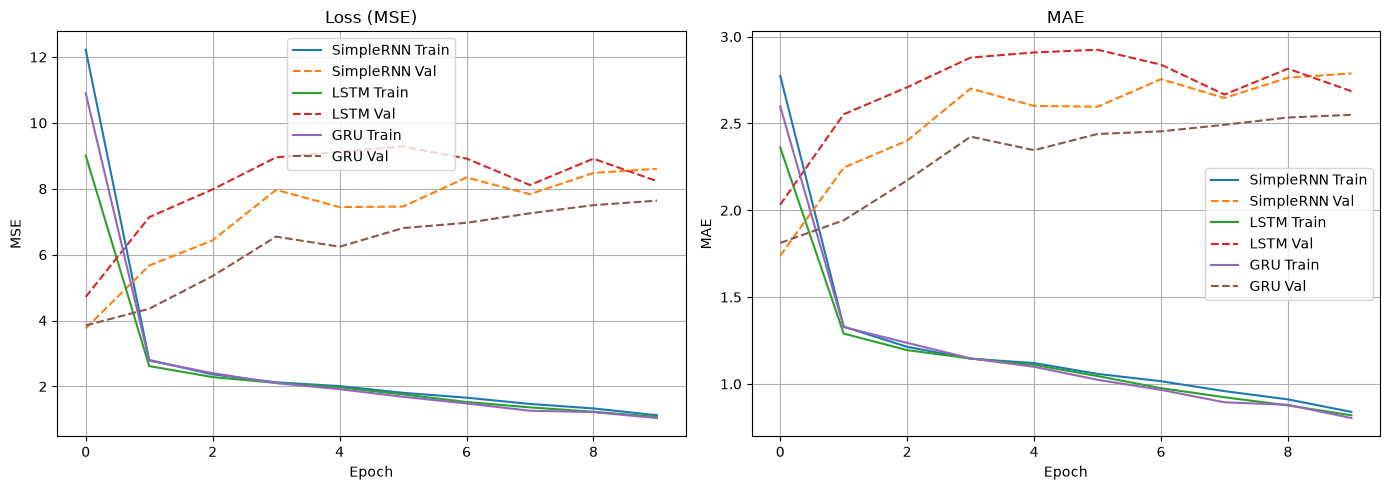

In [45]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
for name, hist in history.items():
    plt.plot(hist["loss"], label=f"{name} Train")
    plt.plot(hist["val_loss"], label=f"{name} Val", linestyle="--")
plt.title("Loss (MSE)")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
for name, hist in history.items():
    plt.plot(hist["mae"], label=f"{name} Train")
    plt.plot(hist["val_mae"], label=f"{name} Val", linestyle="--")
plt.title("MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Predicted vs Actual (Best Model)

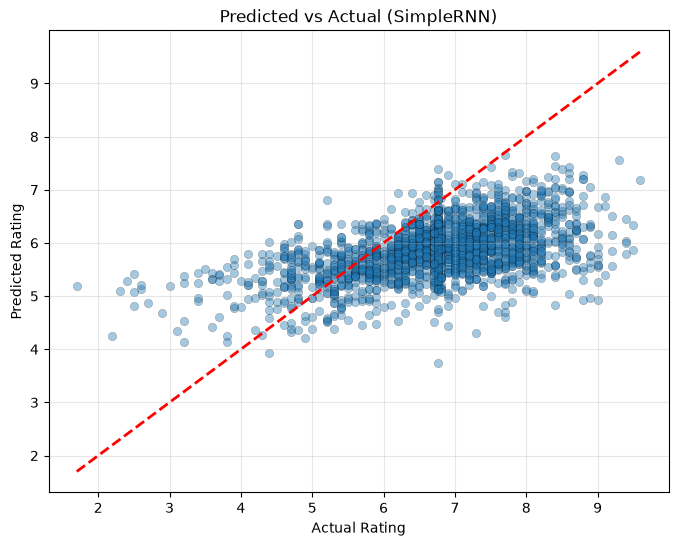

In [46]:
best_model_name = results_df.index[0]
best_model = models[best_model_name]
y_pred_best = best_model.predict(X_test, verbose=0).flatten()

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_best, alpha=0.4, edgecolors="k", linewidth=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2)
plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.title(f"Predicted vs Actual ({best_model_name})")
plt.grid(True, alpha=0.3)
plt.show()

Residual Plot

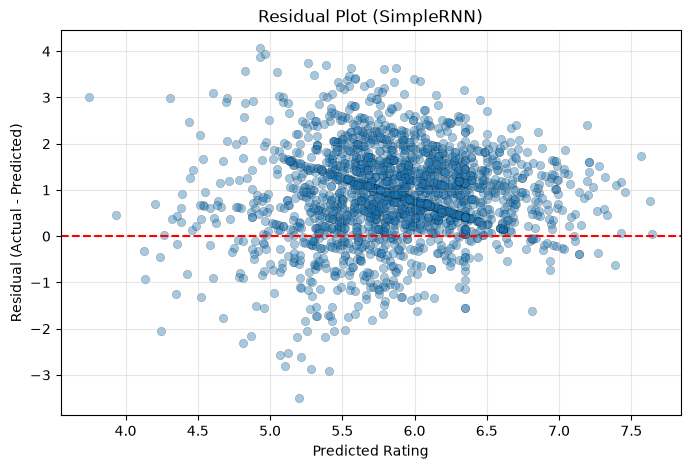

In [47]:
residuals = y_test - y_pred_best
plt.figure(figsize=(8, 5))
plt.scatter(y_pred_best, residuals, alpha=0.4, edgecolors="k", linewidth=0.3)
plt.axhline(y=0, color="r", linestyle="--")
plt.xlabel("Predicted Rating")
plt.ylabel("Residual (Actual - Predicted)")
plt.title(f"Residual Plot ({best_model_name})")
plt.grid(True, alpha=0.3)
plt.show()

Save Best Model + Tokenizer + max_length

In [48]:
best_model.save(f"imdb_rating_{best_model_name.lower()}.h5")
print(f"\nBest model saved as: imdb_rating_{best_model_name.lower()}.h5")

with open("tokenizer_imdb_rating.pickle", "wb") as f:
    pickle.dump(tokenizer, f)
print("Tokenizer saved as: tokenizer_imdb_rating.pickle")

with open("max_length_imdb_rating.pickle", "wb") as f:
    pickle.dump(max_length, f)
print("max_length saved as: max_length_imdb_rating.pickle")


Best model saved as: imdb_rating_simplernn.h5
Tokenizer saved as: tokenizer_imdb_rating.pickle
max_length saved as: max_length_imdb_rating.pickle


Now, I will create UI from these files.